In [1]:
import sys

sys.path.append("../src")

from data_processing.load import load_and_preprocess_data
from models.model import WindPowerModel, WindPowerModel_simple

import jax.numpy as jnp

import torch
from torch import nn, optim
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

### Load data and preprocess

- wind direction transformed from degree using sin and cos
- select one bid zone
- include UMM downtime data
- calculate capacity factor
- scale input features and meta data

Shapes:

- X: (timestamps, wind parks, features)
- Y: (timestamps)
- sites_meta: (wind parks, 1)


In [2]:
from operator import itemgetter

data = load_and_preprocess_data()
(
    X_train,
    X_test,
    Y_train_gen,
    Y_test_gen,
    Y_train_cf,
    Y_test_cf,
    Y_train_aval,
    Y_test_aval,
    sites_meta,
    feature_cols,
) = itemgetter(
    "X_train",
    "X_test",
    "Y_train_gen",
    "Y_test_gen",
    "Y_train_cf",
    "Y_test_cf",
    "Y_train_aval",
    "Y_test_aval",
    "sites_meta",
    "feature_cols",
)(
    data
)

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Preprocessing done. X_train shape: (19130, 6, 6)
Preprocessing done. X_test shape: (2161, 6, 6)


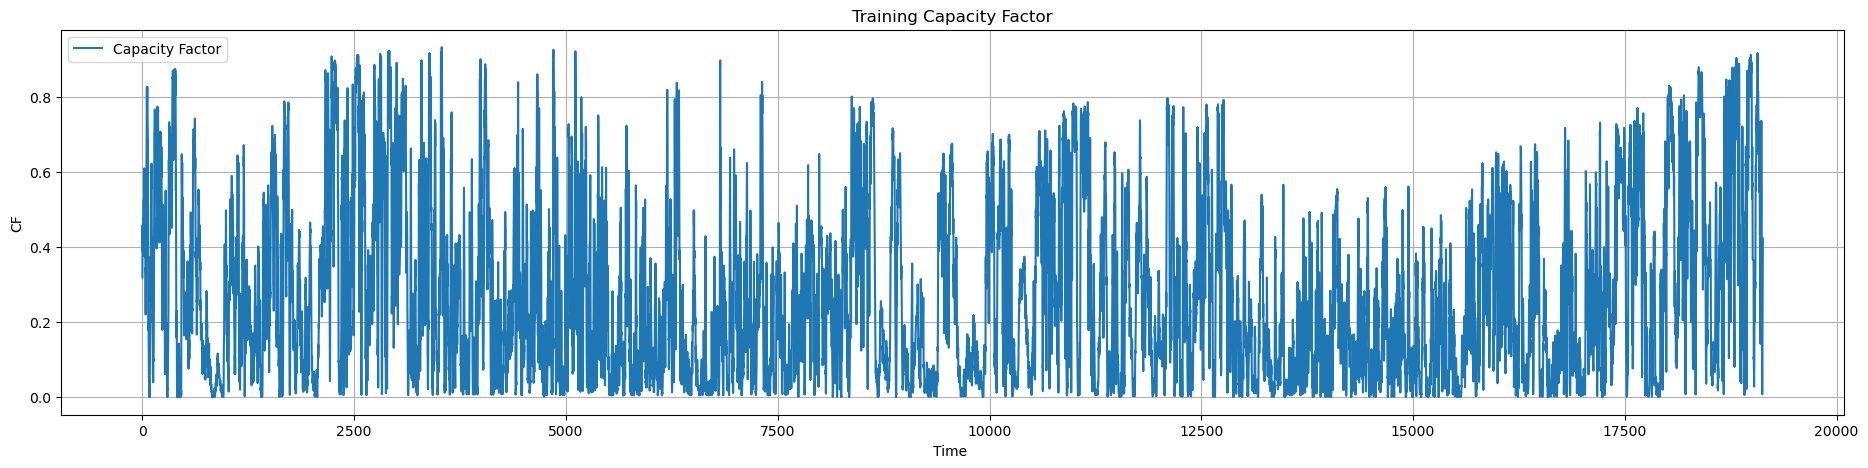

In [3]:
plt.figure(figsize=(23, 5))
plt.plot(Y_train_cf, label="Capacity Factor")
plt.xlabel("Time ")
plt.ylabel("CF")
plt.title("Training Capacity Factor")
plt.legend()
plt.grid(True)
plt.show()

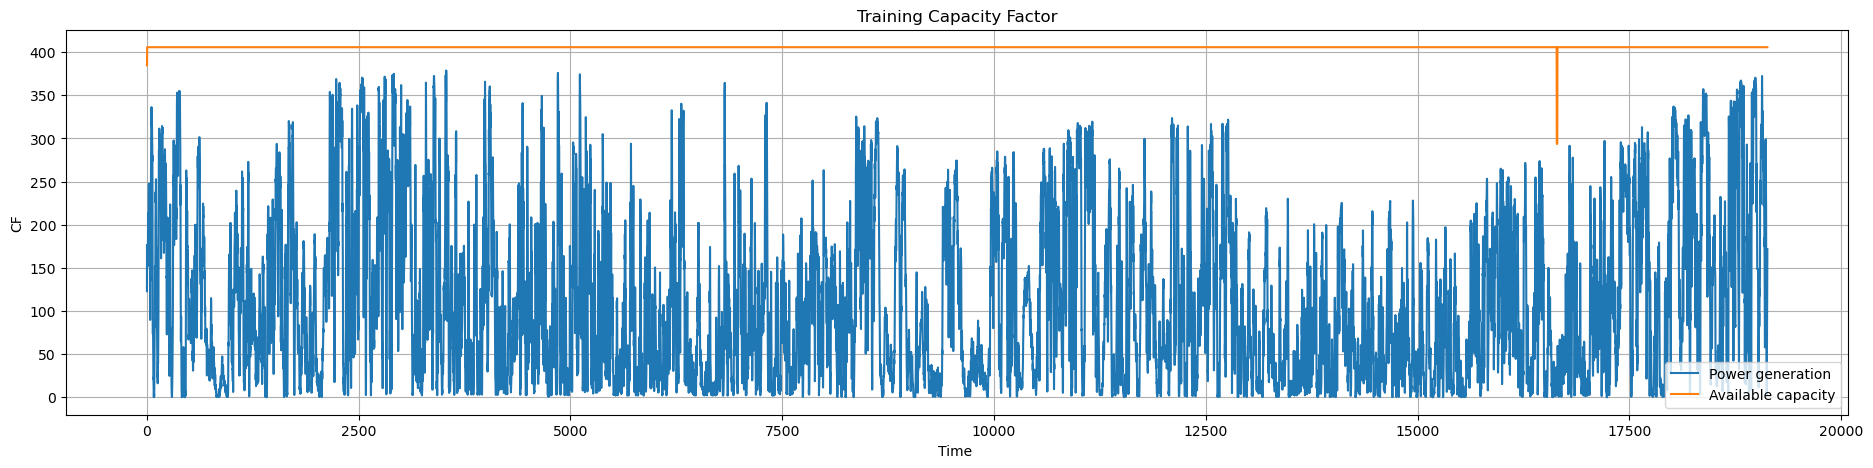

In [4]:
plt.figure(figsize=(23, 5))
plt.plot(Y_train_gen, label="Power generation")
plt.plot(Y_train_aval, label="Available capacity")

plt.xlabel("Time ")
plt.ylabel("CF")
plt.title("Training Capacity Factor")
plt.legend()
plt.grid(True)
plt.show()

### Classic NN

- shared weights for all parks
- wind park specific embeddings (max_operational_power as input) with embed_dim


In [5]:
X_train_tensor = torch.tensor(X_train)
Y_train_cf_tensor = torch.tensor(Y_train_cf)
Y_train_gen_tensor = torch.tensor(Y_train_gen)
X_test_tensor = torch.tensor(X_test)
Y_test_cf_tensor = torch.tensor(Y_test_cf)
sites_meta_tensor = torch.tensor(sites_meta, dtype=torch.float32)

In [6]:
_, num_windparks, num_features = X_train_tensor.shape

In [7]:
nn_model_metainfo = WindPowerModel(num_windparks, num_features, 3, sites_meta.shape[1])
nn_model_simple = WindPowerModel_simple(num_features)


optimizer = optim.Adam(nn_model_simple.parameters(), lr=1e-3)
criterion = nn.MSELoss()

losses = []

for step in range(3000):
    nn_model_metainfo.train()
    optimizer.zero_grad()
    y_site_pred, y_sum_pred = nn_model_simple(X_train_tensor)

    loss = criterion(y_sum_pred, Y_train_cf_tensor)
    losses.append(loss.item())

    loss.backward()
    optimizer.step()

    if step % 250 == 0:
        print(f"Step {step:3d} | Loss: {loss.item():.4f}")

Step   0 | Loss: 0.2529
Step 250 | Loss: 0.0189
Step 500 | Loss: 0.0173
Step 750 | Loss: 0.0168
Step 1000 | Loss: 0.0162
Step 1250 | Loss: 0.0156
Step 1500 | Loss: 0.0153
Step 1750 | Loss: 0.0151
Step 2000 | Loss: 0.0149
Step 2250 | Loss: 0.0148
Step 2500 | Loss: 0.0146
Step 2750 | Loss: 0.0145


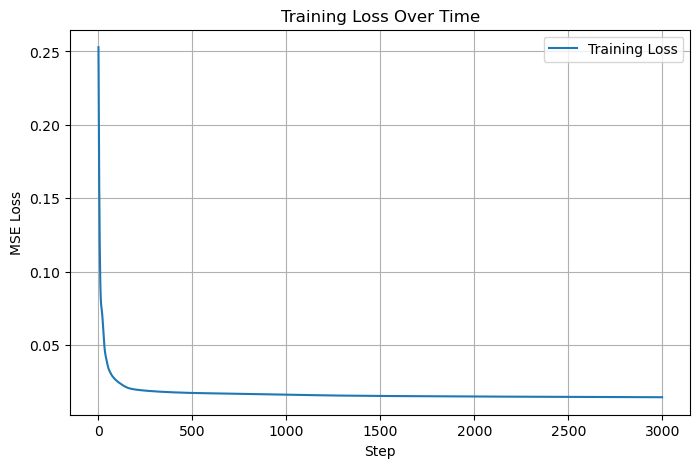

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(losses, label="Training Loss")
plt.xlabel("Step")
plt.ylabel("MSE Loss")
plt.title("Training Loss Over Time")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
nn_model_simple.eval()
with torch.no_grad():
    y_site_pred, y_sum_pred = nn_model_simple(X_test_tensor)

# Rescale to generation prediction
Y_pred = y_sum_pred.numpy() * Y_test_aval
mse = mean_squared_error(Y_test_gen, Y_pred)
rmse = jnp.sqrt(mse)


print(f"Evaluation metrics:")
print(f"RMSE: {rmse:.2f} MW")

Evaluation metrics:
RMSE: 67.95 MW


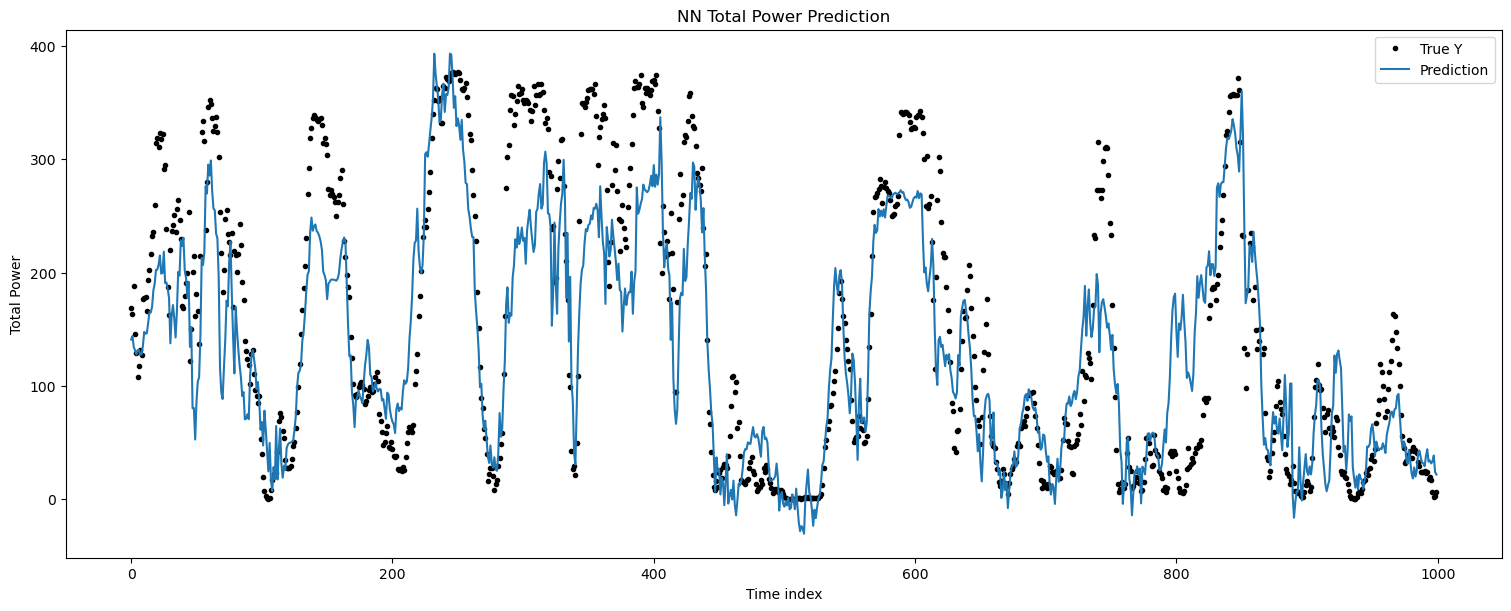

In [10]:
# Plot
n_plot = 1000
fig, ax = plt.subplots(figsize=(15, 6), constrained_layout=True)
ax.plot(Y_test_gen[:n_plot], ".", color="black", label="True Y")
ax.plot(Y_pred[:n_plot], color="C0", label="Prediction")
ax.set(xlabel="Time index", ylabel="Total Power", title="NN Total Power Prediction")
ax.legend()
plt.show()